**CH.SC.U4CSE24142 - SANTHOSH A - DIMENSIONALITY REDUCTION FOR CHECKERBOARD DATASET**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, KernelPCA
from sklearn.manifold import Isomap, LocallyLinearEmbedding, TSNE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
import umap
np.random.seed(42)

In [ ]:
df = pd.read_csv("checkerboard_dataset.csv")
df.head()

,x,y,class
0,0,0,0
1,0,1,1
2,0,2,0
3,0,3,1
4,0,4,0


In [ ]:
print("Shape:", df.shape)
df.info()

Shape: (400, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   x       400 non-null    int64
 1   y       400 non-null    int64
 2   class   400 non-null    int64
dtypes: int64(3)
memory usage: 9.5 KB


In [ ]:
df.describe()

,x,y,class
count,400.000000,400.000000,400.000000
mean,9.500000,9.500000,0.500000
std,5.773503,5.773503,0.500626
min,0.000000,0.000000,0.000000
25%,4.750000,4.750000,0.000000
50%,9.500000,9.500000,0.500000
75%,14.250000,14.250000,1.000000
max,19.000000,19.000000,1.000000


In [ ]:
df.isnull().sum()

,0
x,0
y,0
class,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['class'].value_counts()

,count
class,
0,200
1,200


In [ ]:
X = df[['x', 'y']].values
y = df['class'].values

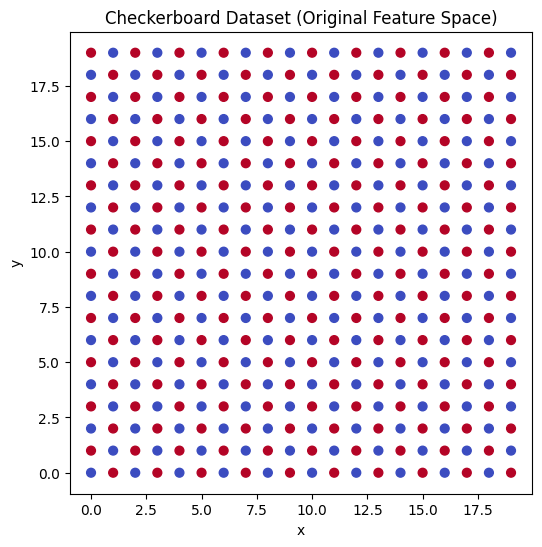

In [ ]:
plt.figure(figsize=(6,6))
plt.scatter(df['x'], df['y'], c=df['class'], cmap='coolwarm', s=40)
plt.title("Checkerboard Dataset (Original Feature Space)")
plt.xlabel("x")
plt.ylabel("y")
plt.gca().set_aspect('equal')
plt.show()

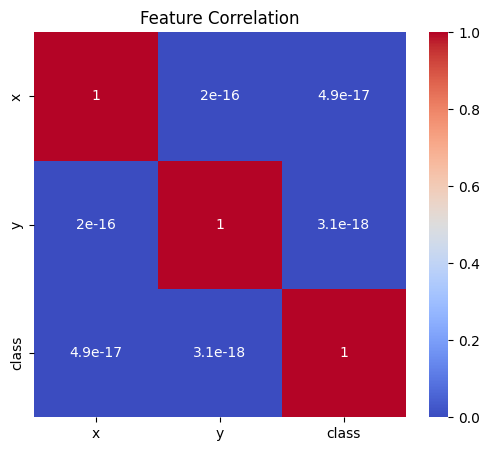

In [ ]:
plt.figure(figsize=(6,5))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title("Feature Correlation")
plt.show()

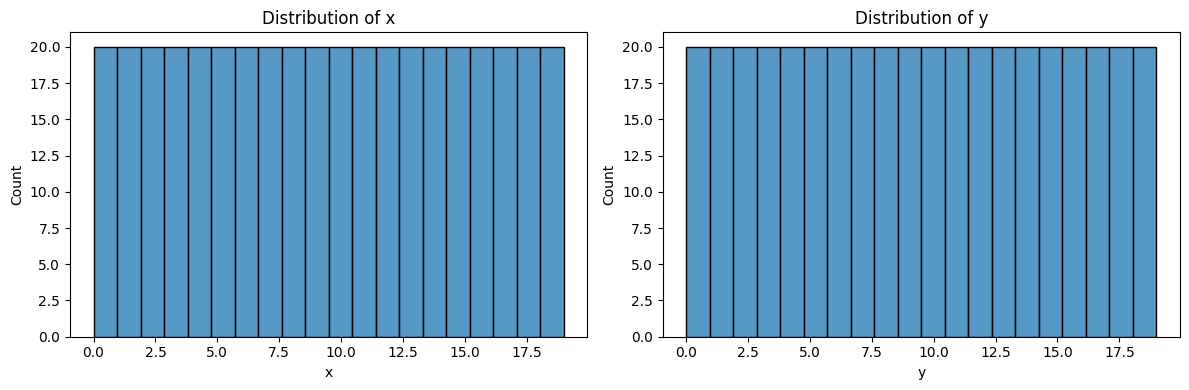

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(df['x'], bins=20, ax=axes[0])
axes[0].set_title("Distribution of x")
sns.histplot(df['y'], bins=20, ax=axes[1])
axes[1].set_title("Distribution of y")
plt.tight_layout()
plt.show()

In [ ]:
X_scaled = StandardScaler().fit_transform(X)
print(X_scaled.shape)

(400, 2)


In [ ]:
def plot_embedding(X_emb, y, title, ax=None):
    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=(6,5))
    ax.scatter(X_emb[:,0], X_emb[:,1], c=y, cmap='coolwarm', s=25)
    ax.set_title(title)
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
    if own_fig:
        plt.show()

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print("Total Variance Captured:", pca.explained_variance_ratio_.sum())

Explained Variance Ratio: [0.5 0.5]
Total Variance Captured: 1.0


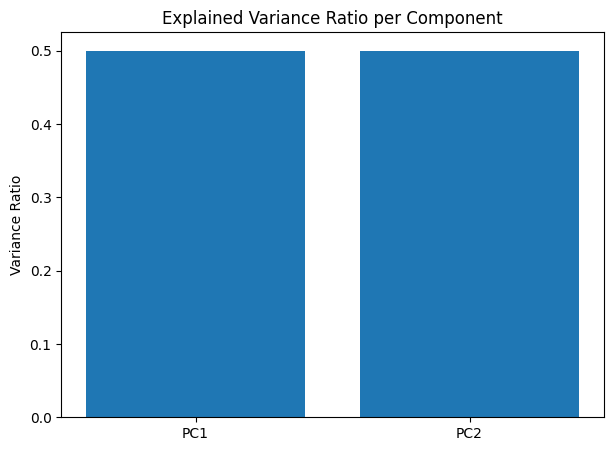

In [ ]:
plt.figure(figsize=(7,5))
plt.bar(['PC1','PC2'], pca.explained_variance_ratio_)
plt.title("Explained Variance Ratio per Component")
plt.ylabel("Variance Ratio")
plt.show()

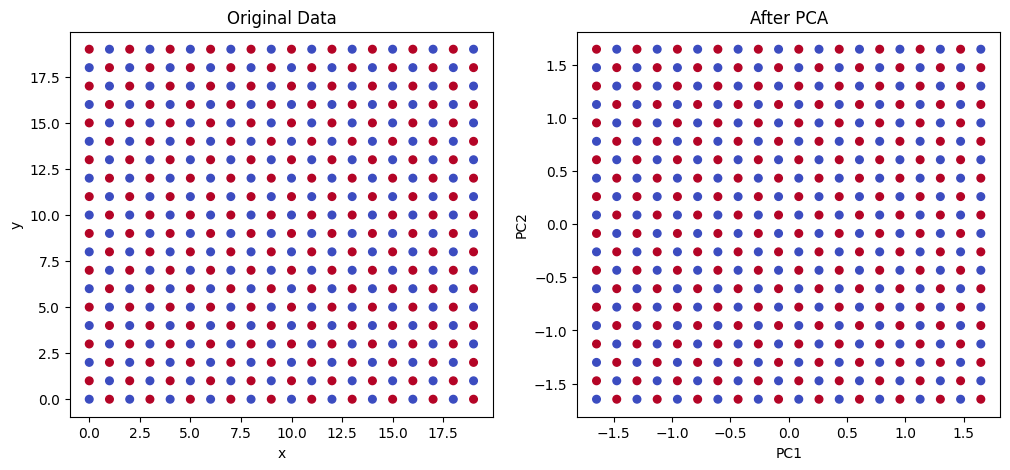

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12,5))
ax[0].scatter(X[:,0], X[:,1], c=y, cmap='coolwarm', s=30)
ax[0].set_title("Original Data")
ax[0].set_xlabel("x")
ax[0].set_ylabel("y")
ax[1].scatter(X_pca[:,0], X_pca[:,1], c=y, cmap='coolwarm', s=30)
ax[1].set_title("After PCA")
ax[1].set_xlabel("PC1")
ax[1].set_ylabel("PC2")
plt.show()

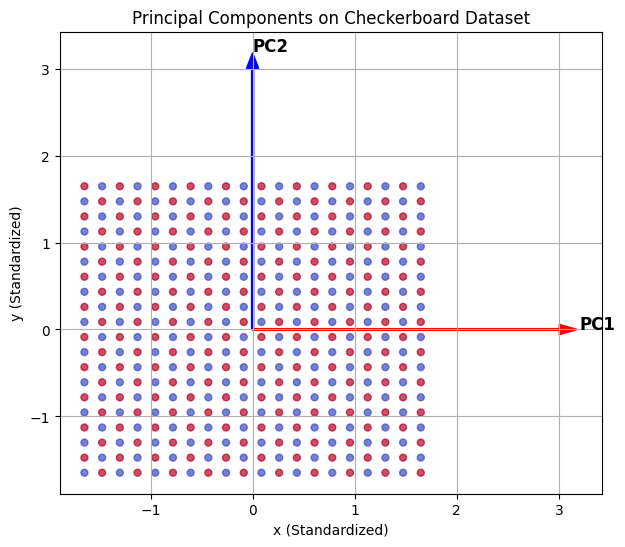

In [ ]:
# Principal axes overlaid on the standardized data
plt.figure(figsize=(7,6))
plt.scatter(X_scaled[:,0], X_scaled[:,1], c=y, cmap='coolwarm', alpha=0.7, s=25)
mean = np.mean(X_scaled, axis=0)
for i, (length, vector) in enumerate(zip(np.sqrt(pca.explained_variance_), pca.components_)):
    plt.arrow(mean[0], mean[1],
              vector[0]*length*3, vector[1]*length*3,
              color='red' if i == 0 else 'blue',
              width=0.02, head_width=0.12)
    plt.text(mean[0] + vector[0]*length*3.2,
             mean[1] + vector[1]*length*3.2,
             f"PC{i+1}", fontsize=12, weight='bold')
plt.xlabel("x (Standardized)")
plt.ylabel("y (Standardized)")
plt.title("Principal Components on Checkerboard Dataset")
plt.grid(True)
plt.show()

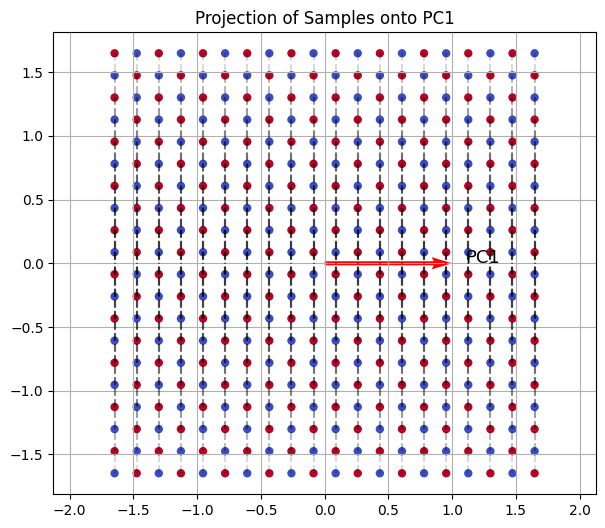

In [ ]:
# Projection of samples onto PC1
pc1 = pca.components_[0]
plt.figure(figsize=(7,6))
plt.scatter(X_scaled[:,0], X_scaled[:,1], c=y, cmap='coolwarm', s=25)
for point in X_scaled:
    projection = np.dot(point, pc1) * pc1
    plt.plot([point[0], projection[0]], [point[1], projection[1]], 'k--', alpha=0.15)
plt.quiver(0, 0, pc1[0], pc1[1], angles='xy', scale_units='xy', scale=1, color='red', linewidth=3)
plt.text(pc1[0]*1.1, pc1[1]*1.1, "PC1", fontsize=13)
plt.title("Projection of Samples onto PC1")
plt.axis('equal')
plt.grid(True)
plt.show()

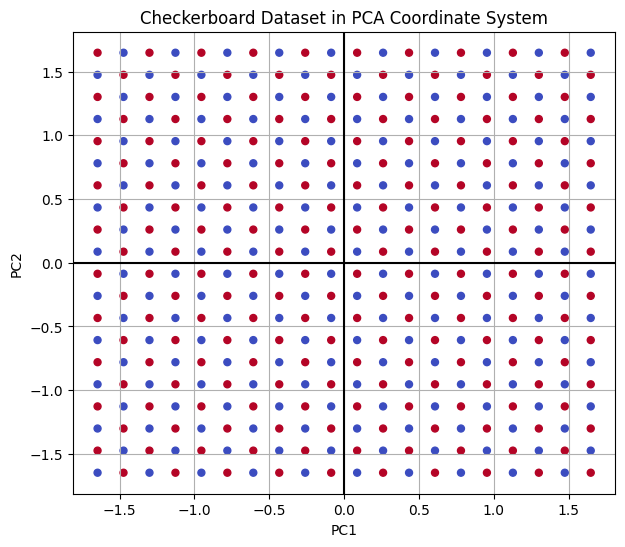

In [ ]:
plt.figure(figsize=(7,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=y, cmap='coolwarm', s=25)
plt.axhline(0, color='black')
plt.axvline(0, color='black')
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Checkerboard Dataset in PCA Coordinate System")
plt.grid(True)
plt.show()

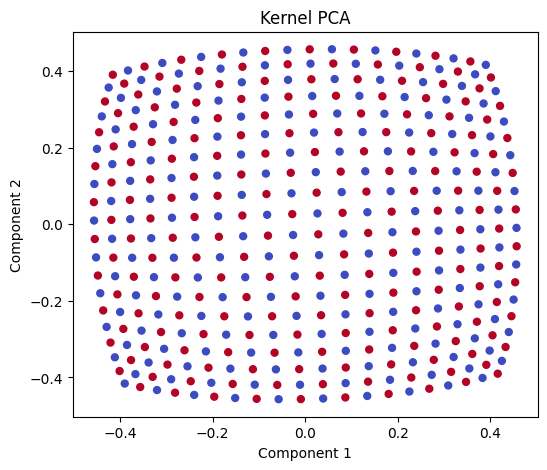

In [ ]:
kpca = KernelPCA(n_components=2, kernel="rbf", gamma=0.05, random_state=42)
X_kpca = kpca.fit_transform(X_scaled)
plot_embedding(X_kpca, y, "Kernel PCA")

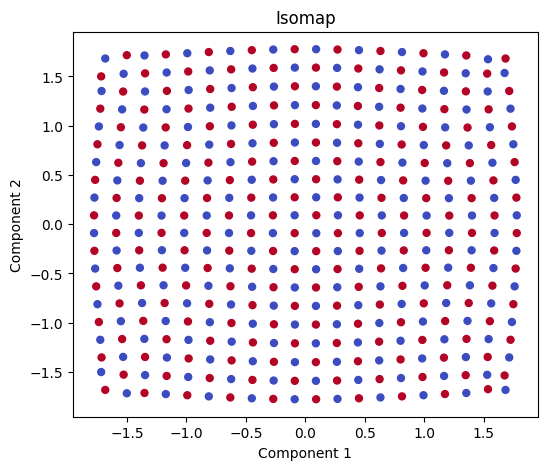

In [ ]:
iso = Isomap(n_components=2, n_neighbors=8)
X_iso = iso.fit_transform(X_scaled)
plot_embedding(X_iso, y, "Isomap")

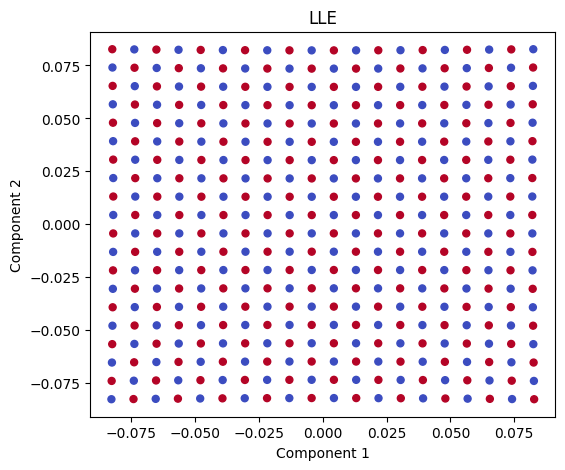

In [ ]:
lle = LocallyLinearEmbedding(n_components=2, n_neighbors=8, random_state=42)
X_lle = lle.fit_transform(X_scaled)
plot_embedding(X_lle, y, "LLE")

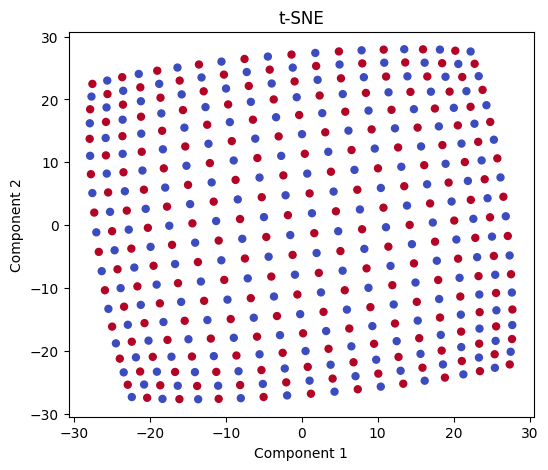

In [ ]:
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)
plot_embedding(X_tsne, y, "t-SNE")

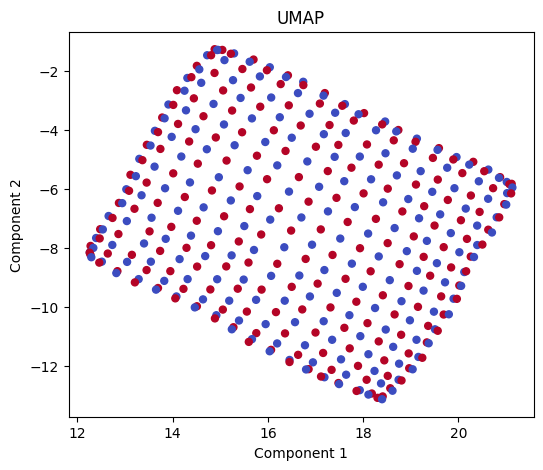

In [ ]:
reducer = umap.UMAP(random_state=42, n_jobs=1)
X_umap = reducer.fit_transform(X_scaled)
plot_embedding(X_umap, y, "UMAP")

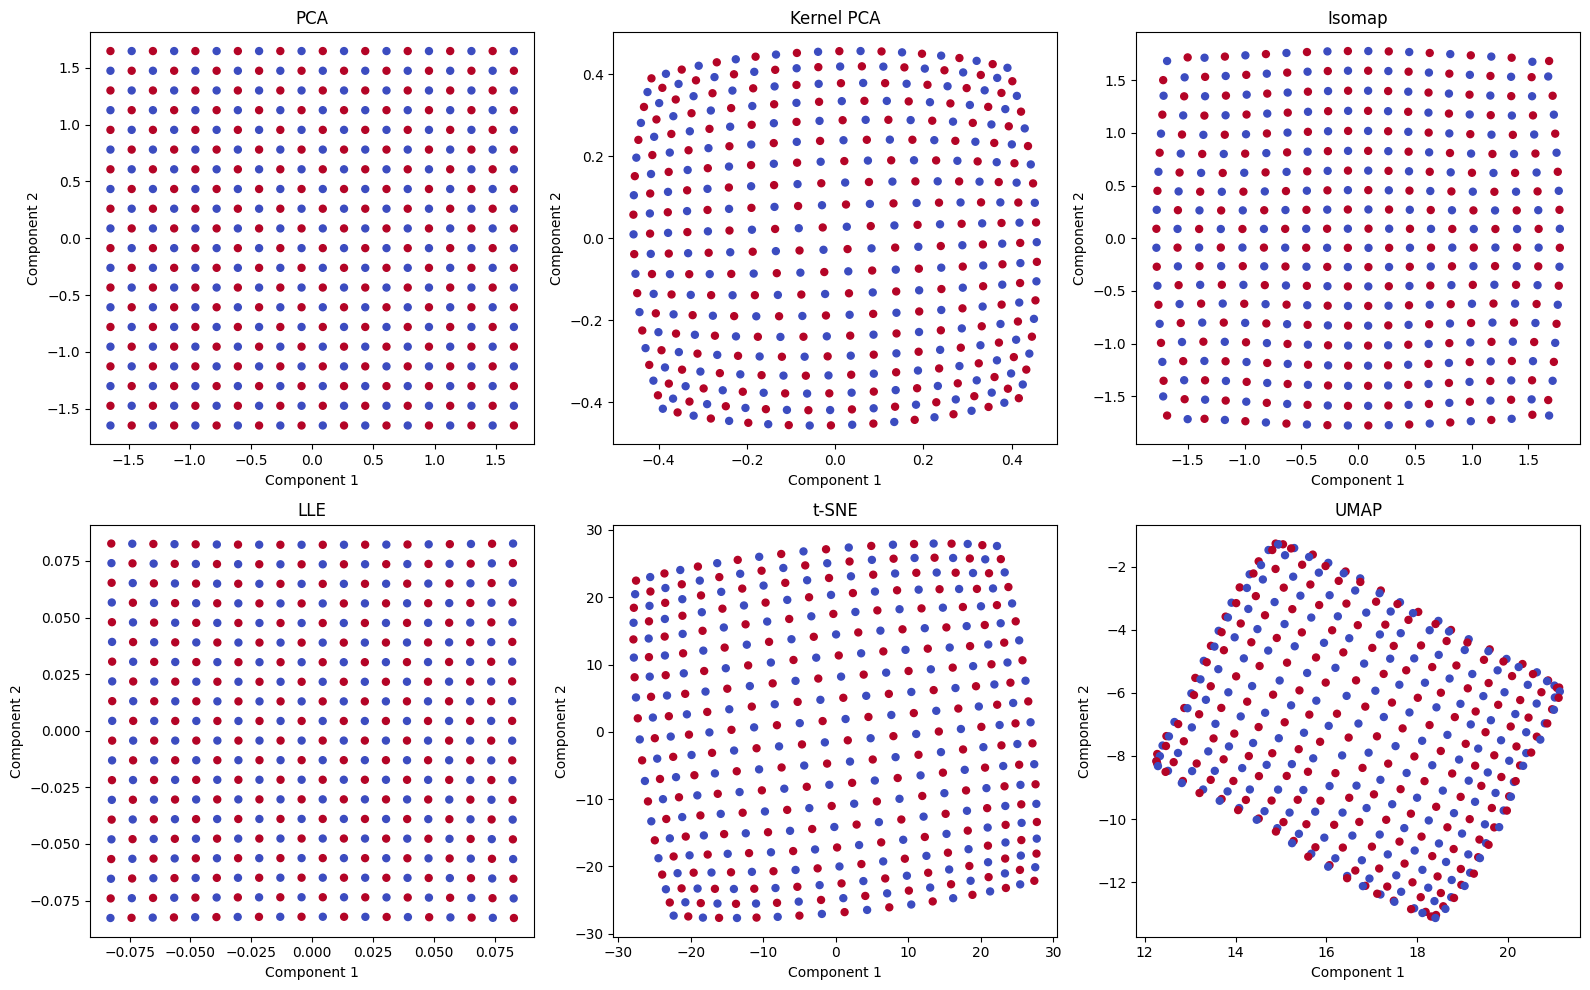

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16,10))
plot_embedding(X_pca, y, "PCA", ax=axes[0,0])
plot_embedding(X_kpca, y, "Kernel PCA", ax=axes[0,1])
plot_embedding(X_iso, y, "Isomap", ax=axes[0,2])
plot_embedding(X_lle, y, "LLE", ax=axes[1,0])
plot_embedding(X_tsne, y, "t-SNE", ax=axes[1,1])
plot_embedding(X_umap, y, "UMAP", ax=axes[1,2])
plt.tight_layout()
plt.show()

In [ ]:
def evaluate(X_in, y_in, name):
    model = LogisticRegression(max_iter=1000)
    scores = cross_val_score(model, X_in, y_in, cv=5)
    acc = scores.mean()
    print(f"{name:12s}: {acc:.4f}")
    return acc
results = {}
results['Original']   = evaluate(X_scaled, y, "Original")
results['PCA']        = evaluate(X_pca,    y, "PCA")
results['Kernel PCA']  = evaluate(X_kpca,  y, "Kernel PCA")
results['Isomap']     = evaluate(X_iso,    y, "Isomap")
results['LLE']        = evaluate(X_lle,    y, "LLE")
results['t-SNE']      = evaluate(X_tsne,   y, "t-SNE")
results['UMAP']       = evaluate(X_umap,   y, "UMAP")

Original    : 0.5000
PCA         : 0.5000
Kernel PCA  : 0.5000
Isomap      : 0.5000
LLE         : 0.5000
t-SNE       : 0.5000
UMAP        : 0.5000


In [ ]:
comparison = pd.DataFrame({
    "Method": list(results.keys()),
    "CV Accuracy (Logistic Regression)": list(results.values())
}).sort_values("CV Accuracy (Logistic Regression)", ascending=False).reset_index(drop=True)
comparison

,Method,CV Accuracy (Logistic Regression)
0,Original,0.5
1,PCA,0.5
2,Kernel PCA,0.5
3,Isomap,0.5
4,LLE,0.5
5,t-SNE,0.5
6,UMAP,0.5


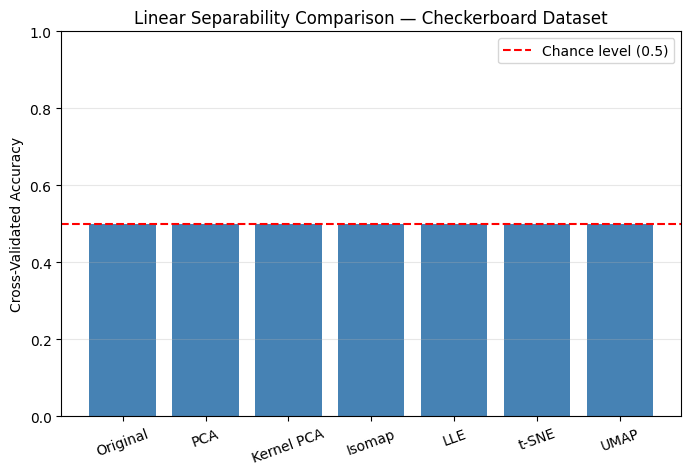

In [ ]:
plt.figure(figsize=(8,5))
plt.bar(comparison["Method"], comparison["CV Accuracy (Logistic Regression)"], color='steelblue')
plt.axhline(0.5, color='red', linestyle='--', label='Chance level (0.5)')
plt.title("Linear Separability Comparison — Checkerboard Dataset")
plt.ylabel("Cross-Validated Accuracy")
plt.xticks(rotation=20)
plt.ylim(0,1)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()